# Multimodal Models for Segmentation via Textual Prompts

> **Environment:** run this notebook on **Kaggle** with a T4 GPU to avoid memory issues or version inconsistencies.

# **Referring Expression Segmentation**

## 1. Environment Setup

### 1.1. Install Dependencies

In [ ]:
import os
!git clone https://github.com/berkeley-hipie/HIPIE
os.chdir('HIPIE')

In [ ]:
!pip3 install --user git+https://github.com/XD7479/cocoapi.git#"egg=pycocotools&subdirectory=PythonAPI"
!pip3 install --user git+https://github.com/lvis-dataset/lvis-api.git
!pip3 install --user git+https://github.com/cocodataset/panopticapi.git
!pip3 install --user git+https://github.com/facebookresearch/segment-anything.git
!pip install -U fvcore iopath portalocker

In [ ]:
!pip uninstall -y torch torchvision torchaudio
!pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install "transformers==4.37.2"
!pip install pillow==9.5.0

In [ ]:
!pip3 install -e . --user

In [ ]:
import os
os.chdir('projects/HIPIE/hipie/models/deformable_detr/ops')
!bash make.sh
os.chdir('../../maskdino/pixel_decoder/ops')
!bash make.sh
os.chdir('../../../../../../..')

### 1.2. Download Weights

In [ ]:
import gdown, os
os.makedirs('/kaggle/working/HIPIE/pretrained_weights', exist_ok=True)
gdown.download(
    f"https://huggingface.co/KonstantinosKK/HIPIE/resolve/main/r50_parts.pth",
    "/kaggle/working/HIPIE/pretrained_weights/r50_parts.pth",
    quiet=False
)

In [ ]:
%cd /kaggle/working/HIPIE
!mkdir -p projects/HIPIE/bert-base-uncased
%cd projects/HIPIE/bert-base-uncased
!wget -c https://huggingface.co/bert-base-uncased/resolve/main/config.json
!wget -c https://huggingface.co/bert-base-uncased/resolve/main/vocab.txt
!wget -c https://huggingface.co/bert-base-uncased/resolve/main/pytorch_model.bin
%cd ../../.

### 1.3. Verify Installation

> **Important:** restart the kernel now (`Kernel → Restart & clear cell outputs`) before running the cells below.

In [ ]:
import torch
print(torch.version.cuda)
print(torch.__version__)

### 1.4. Compatibility Patches

The cells below apply targeted patches to resolve version-specific incompatibilities between the HIPIE codebase and the Kaggle runtime.

In [ ]:
from PIL import Image

# Pillow 10+: LINEAR was removed; it meant bilinear resampling.
if not hasattr(Image, "LINEAR"):
    try:
        Image.LINEAR = Image.Resampling.BILINEAR
    except AttributeError:
        Image.LINEAR = Image.BILINEAR

## 2. Load the HIPIE Model (+ Quick Demo)

In [ ]:
%cd /kaggle/working/HIPIE

In [ ]:
!pip uninstall -y pillow
!pip install --no-cache-dir -U "Pillow==10.4.0"

In [ ]:
from PIL import Image
import tempfile
import time
import warnings
from transformers import AutoTokenizer
import cv2
import numpy as np
import tqdm
import torch
from matplotlib import pyplot as plt

from PIL import Image, _util
import os

if not hasattr(Image, "LINEAR"):
    try:
        Image.LINEAR = Image.Resampling.BILINEAR
    except AttributeError:
        Image.LINEAR = Image.BILINEAR

if not hasattr(_util, "is_directory"):
    def is_directory(f):
        return isinstance(f, (str, bytes, os.PathLike)) and os.path.isdir(f)
    _util.is_directory = is_directory

from detectron2.utils.visualizer import Visualizer
from detectron2.projects.hipie.demo_lib.demo_utils import *
from scipy.ndimage import distance_transform_edt, label as ndi_label

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
from detectron2.data.detection_utils import read_image,convert_PIL_to_numpy

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import requests

def load_image(url):
    response = requests.get(url, stream=True)
    return Image.open(response.raw)

url = "http://images.cocodataset.org/val2017/000000039769.jpg"

image = load_image(url)
prompt = 'left cat'

plt.imshow(image)
plt.axis('off')
plt.show()

In [ ]:
from detectron2.projects.hipie.demo_lib.part_segm_demo import PartSegmDemo


def get_segmentation_mask(image: Image.Image, prompt: str) -> np.ndarray:
    # TODO: Get segmentation mask

    image_np = convert_PIL_to_numpy(image, format="BGR")

    out_dict = demo.foward_reference(
        image_np,
        reference_string=prompt,
        part=None,
        use_coarse=False,
    )

    pred_masks = out_dict["final_mask"]  #(N, H, W)
    if isinstance(pred_masks, torch.Tensor):
        pred_masks = pred_masks.cpu().numpy()

    if pred_masks.ndim == 3:
        if pred_masks.shape[0] == 0:
            h, w = image_np.shape[:2]
            return np.zeros((h, w), dtype=bool)
        out = pred_masks[0].astype(bool)
    else:
        out = pred_masks.astype(bool)

    return out


# TODO: Define auxiliary parameters


CONFIG_FILE = "projects/HIPIE/configs/training/r50_parts.yaml"
WEIGHT_PATH = "/kaggle/working/HIPIE/pretrained_weights/r50_parts.pth"

demo = PartSegmDemo(
    config_file=CONFIG_FILE,
    weight=WEIGHT_PATH,
)
mask = get_segmentation_mask(image, prompt)


# Visualize result
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image", fontsize=12)
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title(f"Predicted Mask: '{prompt}'", fontsize=12)
axes[1].axis('off')

axes[2].imshow(image)
axes[2].imshow(mask, alpha=0.5, cmap='Reds')
axes[2].set_title("Overlay", fontsize=12)
axes[2].axis('off')

plt.suptitle("HIPIE Referring Expression Segmentation Demo", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. RefCOCO Dataset

The **RefCOCO** dataset contains images paired with textual queries and ground-truth masks.

In [ ]:
import os
import gdown
import zipfile
import requests
from pathlib import Path
from tqdm import tqdm


def download_file(url: str, filepath: Path, desc: str = None) -> None:
    """Download a file from URL with progress bar."""
    response = requests.get(url, stream=True)
    total_size = int(response.headers.get('content-length', 0))

    with open(filepath, 'wb') as file, tqdm(
        desc=desc, total=total_size, unit='iB', unit_scale=True, unit_divisor=1024
    ) as pbar:
        for data in response.iter_content(chunk_size=1024):
            size = file.write(data)
            pbar.update(size)


def extract_subset_from_zip(zip_path: Path, extract_dir: Path, max_files: int = 100,
                            extensions: tuple = ('.jpg', '.jpeg', '.png')) -> None:
    """Extract only first N images from zip to save disk space."""
    extract_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zf:
        image_files = [f for f in zf.namelist()
                       if f.lower().endswith(extensions) and not f.startswith('__MACOSX')]
        image_files = sorted(image_files)[:max_files]

        print(f"Extracting {len(image_files)} images (of {len(zf.namelist())} total)...")
        for filename in tqdm(image_files, desc="Extracting"):
            zf.extract(filename, extract_dir)

    print(f"✓ Extracted {len(image_files)} images to {extract_dir}")


def setup_refcoco_dataset(data_dir: Path = Path("/kaggle/working"), max_train_images: int = 100) -> None:
    """Download and extract RefCOCO dataset with COCO train2014 images."""
    coco_dir = data_dir / "coco"
    coco_dir.mkdir(parents=True, exist_ok=True)

    datasets = {
        'train2014': {
            'url': 'http://images.cocodataset.org/zips/train2014.zip',
            'path': coco_dir / 'train2014.zip',
            'limit': max_train_images,
        },
        'refcoco': {
            'gdrive_id': '1r3P1W07uFhAlMm33bD3XwDronj2BZHi9',
            'path': coco_dir / 'refcoco.zip',
            'limit': None,
        }
    }

    for name, dataset in datasets.items():
        zip_path = dataset['path']
        extract_dir = zip_path.parent

        if not zip_path.exists() and not (extract_dir / name).exists():
            print(f"\nDownloading {name}...")
            if 'url' in dataset:
                download_file(dataset['url'], zip_path, desc=name)
            else:
                gdown.download(
                    f"https://drive.google.com/uc?id={dataset['gdrive_id']}",
                    str(zip_path),
                    quiet=False
                )

        if zip_path.exists():
            print(f"\nExtracting {name}...")
            limit = dataset.get('limit')
            if limit is not None:
                extract_subset_from_zip(zip_path, extract_dir, max_files=limit)
            else:
                with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                    zip_ref.extractall(extract_dir)

            zip_path.unlink()
            print(f"Deleted {zip_path} to free space")

    print("\nDataset setup complete!")

In [ ]:
setup_refcoco_dataset(max_train_images=100)

## 4. Dataset Class


In [ ]:
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple
import json
import pickle


@dataclass
class ReferringItem:
    """Single item from RefCOCO dataset."""
    image_path: Path
    captions: List[str]
    bbox: List[float]
    segmentation: List[List[float]]
    image_id: int = None
    ann_id: int = None


class ReferringDataset:
    """RefCOCO dataset wrapper for referring expression segmentation."""

    def __init__(self, data_path: Path, split: str = None, label_type: str = 'google'):
        # TODO: Finish implementation
        # ...
        self.data_path = Path(data_path)
        self.train_img_path = self.data_path / "train2014"
        self.split = split
        self.label_type = label_type
        self.refs, self.bbox_lookup, self.segmentation_lookup = self._load_data()
        print(f"Loaded {len(self.refs)} referring expressions (split={split})")

    def __len__(self) -> int:
        return len(self.refs)

    def __getitem__(self, idx: int) -> ReferringItem:
        # TODO: Finish implementation
        # ...
        if not 0 <= idx < len(self):
            raise IndexError(f"Index {idx} out of bounds for dataset of size {len(self)}")

        ref = self.refs[idx]
        image_id = ref["image_id"]
        ann_id = ref["ann_id"]

        captions = []
        for sent in ref.get("sentences", []):
            captions.append(sent["raw"])

        bbox = self.bbox_lookup.get(ann_id, [])
        segmentation = self.segmentation_lookup.get(ann_id, [])
        image_path = self.get_image_path(image_id)

        return ReferringItem(
            image_path=image_path,
            captions=captions,
            bbox=bbox,
            segmentation=segmentation,
            image_id=image_id,
            ann_id=ann_id,
        )

    def _load_data(self) -> Tuple[List[Dict], Dict, Dict]:
        # TODO: Finish implementation
        # ...
        refs = self._load_annotations(self.data_path / f'refcoco/refs({self.label_type}).p')
        if self.split is not None:
            refs = [ref for ref in refs if ref['split'] == self.split]

        instances = self._load_annotations(self.data_path / "refcoco/instances.json")
        bbox_lookup = {}
        segmentation_lookup = {}
        for ann in instances["annotations"]:
            ann_id = ann["id"]
            bbox_lookup[ann_id] = ann.get("bbox", [])
            segmentation_lookup[ann_id] = ann.get("segmentation", [])
        # segmentation_lookup filled above
        return refs, bbox_lookup, segmentation_lookup

    def get_image_path(self, image_id: int) -> Path:
        return self.train_img_path / f'COCO_train2014_{image_id:012d}.jpg'

    def image_file_exists(self, idx: int) -> bool:
        """True if the COCO train2014 JPEG for this ref exists (needed when only a subset was extracted)."""
        ref = self.refs[idx]
        return self.get_image_path(ref['image_id']).is_file()

    def list_indices_with_images_on_disk(self, max_scan: Optional[int] = None) -> List[int]:
        """Indices whose image file is present under train2014/."""
        n = len(self) if max_scan is None else min(max_scan, len(self))
        return [i for i in range(n) if self.image_file_exists(i)]

    @staticmethod
    def _load_annotations(file_path: Path) -> Any:
        if file_path.suffix == '.json':
            with open(file_path, 'r') as f:
                return json.load(f)
        elif file_path.suffix == '.p':
            with open(file_path, 'rb') as f:
                return pickle.load(f)
        raise ValueError(f"Unsupported file format: {file_path.suffix}")


In [ ]:
DATA_PATH = Path('/kaggle/working/coco')
dataset = ReferringDataset(DATA_PATH, split='test')

EXISTING_IMAGE_INDICES = dataset.list_indices_with_images_on_disk()
NUM_SAMPLES = 5

if len(EXISTING_IMAGE_INDICES) == 0:
    raise FileNotFoundError(
        f"No JPEGs found under {dataset.train_img_path}. "
        "Extract train2014 images (or increase extract count) so paths match RefCOCO image_ids."
    )

samples = [dataset[i] for i in EXISTING_IMAGE_INDICES[:NUM_SAMPLES]]

print(f"Dataset size: {len(dataset)} referring expressions")
print(f"Images on disk (matched refs): {len(EXISTING_IMAGE_INDICES)}")
print(f"Using first {len(samples)} samples that have files on disk")

## 5. Check Performance
One referring phrase per sample (first caption). IoU vs polygon GT;

In [ ]:
from typing import List, Tuple
from tqdm.auto import tqdm
from pycocotools import mask as mask_utils


def _iou(pred_bool: np.ndarray, gt_bool: np.ndarray) -> float:
    # TODO: Finish implementation
    # ...
    pred_bool = pred_bool.astype(bool)
    gt_bool = gt_bool.astype(bool)

    inter = np.logical_and(pred_bool, gt_bool).sum()
    union = np.logical_or(pred_bool, gt_bool).sum()

    if union == 0:
        return 0.0
    iou = inter / union
    return float(iou)


def _polygons_to_mask(segmentation, height: int, width: int) -> np.ndarray:
    """COCO polygons -> bin_mask (H, W)."""
    if segmentation is None or len(segmentation) == 0:
        return np.zeros((height, width), dtype=bool)

    rles = mask_utils.frPyObjects(segmentation, height, width)
    decoded = mask_utils.decode(rles)
    if decoded.ndim == 3:
        gt = decoded.any(axis=-1)
    else:
        gt = decoded.astype(bool)
    return gt


def run_hipie_on_refcoco(
    samples: List[ReferringItem],
    caption_index: int = 0,
    pred_threshold: float = 0.5,
) -> List[Tuple[Image.Image, str, np.ndarray, np.ndarray, float]]:
    """For each sample: first caption → HIPIE mask; IoU vs GT polygon."""
    # TODO: Finish implementation
    # ...
    results = []

    for item in tqdm(samples, desc="HIPIE on RefCOCO"):
        image = Image.open(item.image_path).convert("RGB")
        w, h = image.size

        if len(item.captions) == 0:
            continue
        prompt = item.captions[caption_index]

        pred_mask = get_segmentation_mask(image, prompt)

        gt_mask = _polygons_to_mask(item.segmentation, h, w)

        iou_score = _iou(pred_mask, gt_mask)

        results.append((image, prompt, pred_mask, gt_mask, iou_score))

    return results


def _mask_panel(mask_bool, color_fg, color_bg="#0d1117"):
    import matplotlib.colors as mcolors

    h, w = mask_bool.shape
    rgba = np.zeros((h, w, 4), dtype=np.float32)
    m = mask_bool.astype(bool)
    rgb = np.array(mcolors.to_rgb(color_fg))
    rgba[m, :3] = rgb
    rgba[m, 3] = 1.0
    rgba[~m, :3] = np.array(mcolors.to_rgb(color_bg))
    rgba[~m, 3] = 1.0
    return rgba

def _blend_mask_on_image(rgb_uint8, mask_bool, rgb_color, alpha=0.62):
    base = rgb_uint8.astype(np.float32) / 255.0
    c = np.array(rgb_color, dtype=np.float32) / 255.0
    m = mask_bool.astype(bool)
    out = base.copy()
    out[m] = base[m] * (1.0 - alpha) + c * alpha
    return np.clip(out * 255.0, 0, 255).astype(np.uint8)


def plot_refcoco_inference_rows(results, max_plots: int = 8):
    COL_PRED = (0, 245, 255)   # cyan
    COL_GT = (80, 255, 120)    # lime
    COL_OVERLAY_PRED = (255, 70, 140)
    COL_OVERLAY_GT = (40, 255, 200)

    for k, (img, prompt, pred, gt, iou_score) in enumerate(results[:max_plots]):
        arr = np.asarray(img)
        if arr.ndim == 2:
            arr = np.stack([arr] * 3, axis=-1)

        fig, axes = plt.subplots(
            1, 4,
            figsize=(17, 4.2),
            gridspec_kw={"wspace": 0.08, "left": 0.02, "right": 0.98, "top": 0.82, "bottom": 0.06},
        )

        titles = ["Input image", "Prediction", "Ground truth", "Overlay + IoU"]
        for ax, title in zip(axes, titles):
            ax.set_title(title, fontsize=11, fontweight="bold", pad=8, color="#1a1a1a")

        axes[0].imshow(arr)
        axes[0].set_facecolor("#f0f2f5")

        axes[1].imshow(_mask_panel(pred, "#00e5ff", "#121826"))
        axes[2].imshow(_mask_panel(gt, "#56ff7a", "#121826"))

        both = _blend_mask_on_image(arr, pred, COL_OVERLAY_PRED, alpha=0.58)
        both = _blend_mask_on_image(both, gt, COL_OVERLAY_GT, alpha=0.52)
        axes[3].imshow(both)

        iou_color = "#0a8f3c" if iou_score >= 0.5 else ("#c97800" if iou_score >= 0.25 else "#c62828")
        axes[3].set_title(
            f"IoU = {iou_score:.3f}",
            fontsize=12,
            fontweight="bold",
            color=iou_color,
            pad=8,
        )
        for ax in axes:
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1.2)
                spine.set_edgecolor("#cfd8dc")

        short = prompt if len(prompt) < 100 else prompt[:97] + "…"
        fig.suptitle(
            short,
            fontsize=11,
            y=0.98,
            wrap=True,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="#e3f2fd", edgecolor="#90caf9", linewidth=1),
        )
        plt.show()


In [ ]:
refcoco_results = run_hipie_on_refcoco(samples)
plot_refcoco_inference_rows(refcoco_results)

Everything looks good, right?...

## 6. Negative Prompting
Negative prompts describe objects absent from an image. Since the RefCOCO benchmark lacks such examples, we evaluate model performance using prompts unrelated to the selected image. Specifically, if the cosine similarity between the original and negative prompt is below a threshold (e.g., < 0.5), the prompts are considered unrelated. A more advanced method involves using a language or vision-language model to determine if a prompt refers to an image or not.

In [ ]:
import random

NUM_UNRELATED_PROMPTS = 8

_GENERIC_UNRELATED = [
    # You can add more prompts here / change existing ones
    "the red stop sign on the corner",
    "a person wearing a yellow helmet",
    "the tennis racket next to the net",
    "a large white cruise ship",
    "the giraffe behind the fence",
    "a microwave oven on the counter",
    "the motorcycle parked on the street",
    "a slice of pizza on a plate",
    "the traffic light showing green",
    "a snowboard leaning against the wall",
    "the boat floating on the lake"
]


def _seven_unrelated_prompts(
    item: ReferringItem,
    pool_items: List[ReferringItem],
    rng: random.Random = 42,
    n: int = NUM_UNRELATED_PROMPTS,
) -> List[str]:
    """Up to n distinct short captions from other images, then generic fillers."""
    others = [x for x in pool_items if x.image_id != item.image_id]
    rng.shuffle(others)
    prompts: List[str] = []
    for o in others:
        if not o.captions:
            continue
        t = o.captions[0].strip()
        if t and t not in prompts:
            prompts.append(t)
        if len(prompts) >= n:
            return prompts[:n]
    gen = list(_GENERIC_UNRELATED)
    rng.shuffle(gen)
    for t in gen:
        if t not in prompts:
            prompts.append(t)
        if len(prompts) >= n:
            return prompts[:n]
    k = 0
    while len(prompts) < n:
        prompts.append(f"{rng.choice(_GENERIC_UNRELATED)} ({k})")
        k += 1
    return prompts[:n]


def run_hipie_negative_prompts(
    samples: List[ReferringItem],
    dataset: ReferringDataset,
    existing_indices: List[int],
    pred_threshold: float = 0.5,
    seed: int = 42,
) -> List[Tuple[Image.Image, np.ndarray, List[Tuple[str, np.ndarray, float]], str]]:
    """Per sample: GT mask + NUM_UNRELATED_PROMPTS HIPIE masks from unrelated text.

    Returns list of (image, gt_bool, [(prompt, pred_bool, iou), ...×7], true_caption).
    """
    rng = random.Random(seed)
    pool_items = [dataset[i] for i in existing_indices]

    out = []

    for item in tqdm(samples, desc="HIPIE negative prompts"):
        # TODO: Finish implementation
        # ...
        image = Image.open(item.image_path).convert("RGB")
        w, h = image.size

        gt_mask = _polygons_to_mask(item.segmentation, h, w)

        true_caption = item.captions[0] if item.captions else ""

        neg_prompts = _seven_unrelated_prompts(item, pool_items, rng=rng)

        per_prompt = []
        for prompt in neg_prompts:
            # TODO: Finish implementation
            # ...
            pred_mask = get_segmentation_mask(image, prompt)
            iou_score = _iou(pred_mask, gt_mask)
            per_prompt.append((prompt, pred_mask, iou_score))

        out.append((image, gt_mask, per_prompt, true_caption))

    return out


def plot_refcoco_negative_rows(results, max_plots: int = 8):
    pred_colors = ["#00e5ff", "#ff6ec7", "#b388ff", "#69f0ae", "#ffd740", "#ff8a65", "#80d8ff"]

    for row in results[:max_plots]:
        img, gt_bool, triples, true_caption = row
        arr = np.asarray(img)
        if arr.ndim == 2:
            arr = np.stack([arr] * 3, axis=-1)

        ncols = 2 + len(triples)
        fig_w = 2.1 * ncols
        fig, axes = plt.subplots(
            1,
            ncols,
            figsize=(fig_w, 3.9),
            gridspec_kw={"wspace": 0.12, "left": 0.02, "right": 0.98, "top": 0.82, "bottom": 0.18},
        )
        if ncols == 1:
            axes = [axes]

        axes[0].imshow(arr)
        axes[0].set_title("Image", fontsize=11, fontweight="bold", pad=6)
        axes[0].set_facecolor("#f0f2f5")

        _, first_pred, _ = triples[0]
        gt_display = gt_bool
        if gt_display.shape != first_pred.shape:
            gt_display = cv2.resize(
                gt_bool.astype(np.uint8),
                (first_pred.shape[1], first_pred.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            ).astype(bool)

        axes[1].imshow(_mask_panel(gt_display, "#56ff7a", "#121826"))
        axes[1].set_title("GT mask", fontsize=11, fontweight="bold", pad=6)

        for j, (prompt, pred, iou_score) in enumerate(triples):
            ax = axes[2 + j]
            ax.imshow(_mask_panel(pred, pred_colors[j % len(pred_colors)], "#121826"))
            short = (prompt[:42] + "…") if len(prompt) > 43 else prompt
            ax.set_title(f"U{j + 1}\n{short}", fontsize=7, pad=4)
            ax.set_xlabel(f"IoU={iou_score:.2f}", fontsize=8, color="#555")

        for ax in axes:
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1.0)
                spine.set_edgecolor("#cfd8dc")

        st = true_caption if len(true_caption) < 120 else true_caption[:117] + "…"
        fig.suptitle(
            f"GT refers to: {st}",
            fontsize=10,
            y=1.02,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="#e8f5e9", edgecolor="#66bb6a", linewidth=1),
        )
        plt.show()


In [ ]:
refcoco_neg_results = run_hipie_negative_prompts(samples, dataset, EXISTING_IMAGE_INDICES, seed=123)
plot_refcoco_negative_rows(refcoco_neg_results)

What conclusions can be made?

# **Reasoning Segmentation**

This part of the notebook explores **LISA**, a reasoning segmentation model that combines a large language model (LLaMA in LLaVA) with the SAM decoder to produce segmentation masks from natural-language prompts.

> **Important:** it is recommended to do `Factory reset` at this point

## 1. Environment Setup

### 1.1. Install Dependencies

In [ ]:
!git clone https://github.com/dvlab-research/LISA.git
import os
os.chdir("LISA")

In [ ]:
%%writefile requirements.txt
packaging
sentencepiece
peft==0.4.0
einops==0.4.1
fastapi==0.100.1
gradio==3.39.0
markdown2==2.4.10
openai==0.27.8
opencv_python==4.8.0.74
Pillow==9.4.0
pycocotools==2.0.6
Requests==2.31.0
shortuuid==1.0.11
tqdm==4.64.1

In [ ]:
!pip install -r requirements.txt
!pip install numpy ray uvicorn scipy bitsandbytes
!pip install transformers==4.34
!pip install --force-reinstall "numpy<2"
!python -m pip uninstall -y huggingface_hub
!python -m pip install --no-cache-dir --force-reinstall "huggingface_hub==0.23.4"

### 1.2. Verify Installation

> **Important:** restart the kernel now (`Kernel → Restart & clear cell outputs`) before running the cells below.

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import transformers, huggingface_hub
print("transformers:", transformers.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
from huggingface_hub import split_torch_state_dict_into_shards
print("Installation OK")

transformers: 4.34.0
huggingface_hub: 0.23.4
Installation OK


### 1.3. Compatibility Patches

The cells below apply targeted patches to resolve version-specific incompatibilities between the LISA codebase and the Kaggle runtime.

In [ ]:
import os, sys
os.chdir("/kaggle/working/HIPIE/LISA")
if "/kaggle/working/LISA" not in sys.path:
    sys.path.insert(0, "/kaggle/working/LISA")

In [ ]:
from transformers import AutoConfig, AutoModelForCausalLM

_orig_cfg_register = AutoConfig.register
def _safe_cfg_register(model_type, config, exist_ok=False):
    if model_type == "llava":
        exist_ok = True
    return _orig_cfg_register(model_type, config, exist_ok=exist_ok)
AutoConfig.register = _safe_cfg_register

_orig_model_register = AutoModelForCausalLM.register
def _safe_model_register(config_class, model_class, exist_ok=False):
    try:
        return _orig_model_register(config_class, model_class, exist_ok=exist_ok)
    except (ValueError, KeyError):
        return None
AutoModelForCausalLM.register = _safe_model_register

In [ ]:
import accelerate.big_modeling as bm
import transformers.modeling_utils as mu

_orig_bm_dispatch = bm.dispatch_model

def _safe_dispatch(model, *args, **kwargs):
    if getattr(model, "quantization_method", None) is not None:
        return model
    return _orig_bm_dispatch(model, *args, **kwargs)

bm.dispatch_model = _safe_dispatch
mu.dispatch_model = _safe_dispatch

/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:311: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


In [ ]:
import torch
import transformers.models.llama.modeling_llama as llama_mod

_orig_apply_rotary = llama_mod.apply_rotary_pos_emb

def _patched_apply_rotary_pos_emb(q, k, cos, sin, position_ids):
    target = q.device
    cos = cos.to(target)
    sin = sin.to(target)
    if position_ids is not None:
        position_ids = position_ids.to(target)
    return _orig_apply_rotary(q, k, cos, sin, position_ids)

llama_mod.apply_rotary_pos_emb = _patched_apply_rotary_pos_emb
print("All patches applied.")

All patches applied.


### 1.4. Fix Seeds


In [ ]:
import os
import random
import numpy as np

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

    import torch
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    from transformers import set_seed
    set_seed(seed)

    print(f"✅ All random seeds fixed to: {seed}")

seed_everything(42)

2026-04-27 21:07:11.866605: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777324031.889482    1610 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777324031.896722    1610 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777324031.914872    1610 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777324031.914902    1610 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777324031.914905    1610 computation_placer.cc:177] computation placer alr

✅ All random seeds fixed to: 42


## 2. Load the LISA Model

In [ ]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from pprint import pprint
from transformers import AutoTokenizer, BitsAndBytesConfig, CLIPImageProcessor

# TODO: Add all necessary imports here
# ...
from model.LISA import LISAForCausalLM
from model.llava import conversation as conversation_lib
from model.llava.mm_utils import tokenizer_image_token
from model.llava.constants import (
    DEFAULT_IM_END_TOKEN,
    DEFAULT_IM_START_TOKEN,
    DEFAULT_IMAGE_TOKEN,
    IMAGE_TOKEN_INDEX,
)
from model.segment_anything.utils.transforms import ResizeLongestSide


/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:311: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


In [ ]:
VERSION = "xinlai/LISA-13B-llama2-v1"

# TODO: Load tokenizer here
# ...
tokenizer = AutoTokenizer.from_pretrained(
    VERSION,
    cache_dir=None,
    model_max_length=512,
    padding_side="right",
    use_fast=False,
)

tokenizer.pad_token = tokenizer.unk_token

tokenizer.add_tokens("[SEG]")
seg_token_idx = tokenizer("[SEG]", add_special_tokens=False).input_ids[0]

tokenizer.add_tokens(
    [DEFAULT_IM_START_TOKEN, DEFAULT_IM_END_TOKEN], special_tokens=True
)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


0

In [ ]:
# TODO: Load model in 4-bit mode here
# ...
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
)

torch_dtype = torch.float16

model = LISAForCausalLM.from_pretrained(
    VERSION,
    torch_dtype=torch_dtype,
    quantization_config=bnb_config,
    low_cpu_mem_usage=True,
    seg_token_idx=seg_token_idx,
)

model.config.eos_token_id = tokenizer.eos_token_id
model.config.bos_token_id = tokenizer.bos_token_id
model.config.pad_token_id = tokenizer.pad_token_id


pytorch_model.bin.index.json: 0.00B [00:00, ?B/s]

pytorch_model-00001-of-00003.bin:   0%|          | 0.00/9.95G [00:00<?, ?B/s]

pytorch_model-00002-of-00003.bin:   0%|          | 0.00/9.90G [00:00<?, ?B/s]

pytorch_model-00003-of-00003.bin:   0%|          | 0.00/8.86G [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/modeling_utils.py:484: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(checkpoint_file, map_location=map

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [ ]:
# TODO: Load vision modules
# ...
model.get_model().initialize_vision_modules(model.get_model().config)
vision_tower = model.get_model().get_vision_tower()
vision_tower.to(dtype=torch_dtype)

clip_image_processor = CLIPImageProcessor.from_pretrained(model.config.vision_tower)

transform = ResizeLongestSide(1024)

vision_tower = vision_tower.cuda()

model.eval()


LISAForCausalLM(
  (model): LisaModel(
    (embed_tokens): Embedding(32003, 5120, padding_idx=0)
    (layers): ModuleList(
      (0-39): 40 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (k_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (v_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (o_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear4bit(in_features=5120, out_features=13824, bias=False)
          (up_proj): Linear4bit(in_features=5120, out_features=13824, bias=False)
          (down_proj): Linear4bit(in_features=13824, out_features=5120, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm()
        (post_attention_layernorm): LlamaRMSNorm()
      )
  

## 3. Inference Pipeline

In [ ]:
# TODO: Define used parameters of the model here
# ...

PARAMETERS = {
    "image_size_clip": 224,
    "image_size_sam": 1024,
    "max_new_tokens": 512,
    "conv_type": "llava_v1",
    "use_mm_start_end": True,
    "pixel_mean": [0.48145466, 0.4578275, 0.40821073],
    "pixel_std":  [0.26862954, 0.26130258, 0.27577711],
    "sam_pixel_mean": [123.675, 116.28, 103.53],
    "sam_pixel_std":  [58.395, 57.12, 57.375],
}


In [ ]:
# TODO: Add here helper functions
# ...

def preprocess_clip(image_rgb, params=PARAMETERS):
    """для CLIP"""
    image_clip = clip_image_processor.preprocess(image_rgb, return_tensors="pt")["pixel_values"][0]
    image_clip = image_clip.unsqueeze(0).cuda().to(torch_dtype)
    return image_clip


def preprocess_sam(image_rgb, params=PARAMETERS):
    """для SAM"""
    image_size_sam = params["image_size_sam"]

    image_sam = transform.apply_image(image_rgb)
    resize_shape = image_sam.shape[:2]

    image_sam = torch.from_numpy(image_sam).permute(2, 0, 1).contiguous().float()

    pixel_mean = torch.tensor(params["sam_pixel_mean"]).view(-1, 1, 1)
    pixel_std = torch.tensor(params["sam_pixel_std"]).view(-1, 1, 1)
    image_sam = (image_sam - pixel_mean) / pixel_std

    h, w = image_sam.shape[-2:]
    pad_h = image_size_sam - h
    pad_w = image_size_sam - w
    image_sam = F.pad(image_sam, (0, pad_w, 0, pad_h))

    image_sam = image_sam.unsqueeze(0).cuda().to(torch_dtype)
    return image_sam, resize_shape


def build_prompt(prompt: str, params=PARAMETERS) -> str:

    conv = conversation_lib.conv_templates[params["conv_type"]].copy()
    conv.messages = []

    if params["use_mm_start_end"]:
        image_token = DEFAULT_IM_START_TOKEN + DEFAULT_IMAGE_TOKEN + DEFAULT_IM_END_TOKEN
    else:
        image_token = DEFAULT_IMAGE_TOKEN

    user_message = image_token + "\n" + prompt
    conv.append_message(conv.roles[0], user_message)
    conv.append_message(conv.roles[1], None)
    return conv.get_prompt()


@torch.no_grad()
def run_inference(prompt, image_path, params=PARAMETERS):
    # TODO: Finish implementation
    # ...

    image_bgr = cv2.imread(image_path)
    image_rgb = image_bgr[..., ::-1]
    original_size = image_rgb.shape[:2]

    image_clip = preprocess_clip(image_rgb, params)
    image_sam, resize_shape = preprocess_sam(image_rgb, params)

    full_prompt = build_prompt(prompt, params)
    input_ids = tokenizer_image_token(full_prompt, tokenizer, return_tensors="pt")
    input_ids = input_ids.unsqueeze(0).cuda()

    output_ids, pred_masks = model.evaluate(
        image_clip,
        image_sam,
        input_ids,
        [resize_shape],
        [original_size],
        max_new_tokens=params["max_new_tokens"],
        tokenizer=tokenizer,
    )

    output_ids = output_ids[0][output_ids[0] != IMAGE_TOKEN_INDEX]
    text_output = tokenizer.decode(output_ids, skip_special_tokens=False)

    return text_output, pred_masks


In [ ]:
def overlay_mask(image_np, pred_mask, color=(255, 0, 0), alpha=0.5):
    mask = pred_mask.detach().cpu().numpy()[0] > 0
    overlay = image_np.copy()
    overlay[mask] = (
        image_np * (1 - alpha)
        + mask[:, :, None].astype(np.uint8) * np.array(color) * alpha
    )[mask]
    return overlay


def show_segmentation(image_path, pred_masks, title=""):
    image_np = cv2.imread(image_path)[..., ::-1]
    fig, axes = plt.subplots(1, max(len(pred_masks), 1) + 1, figsize=(6 * (len(pred_masks) + 1), 5))
    if not isinstance(axes, np.ndarray):
        axes = [axes]
    axes[0].imshow(image_np)
    axes[0].set_title("Original")
    axes[0].axis("off")
    for i, pm in enumerate(pred_masks):
        axes[i + 1].imshow(overlay_mask(image_np, pm))
        axes[i + 1].set_title(f"Mask {i}")
        axes[i + 1].axis("off")
    if title:
        fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

### 3.1. Text-Only Question Answering

When the prompt does **not** ask for a segmentation mask, LISA behaves like a standard VQA model and returns text only.

In [ ]:
text_output, pred_masks = run_inference(
    prompt="Who was the president of the US in this image?",
    image_path="imgs/obama.jpg",
)
print("Model response:", text_output.split("ASSISTANT: ")[-1] if "ASSISTANT:" in text_output else text_output)
print("Masks returned:", len(pred_masks), "— shape:", [m.shape for m in pred_masks])

/usr/local/lib/python3.12/dist-packages/transformers/generation/utils.py:1421: UserWarning: You have modified the pretrained model configuration to control generation. This is a deprecated strategy to control generation and will be removed soon, in a future version. Please use and modify the model generation configuration (see https://huggingface.co/docs/transformers/generation_strategies#default-text-generation-configuration )
  warnings.warn(


Model response: The President of the US in this image is President Obama.</s>
Masks returned: 1 — shape: [torch.Size([0, 409, 594])]


### 3.2. Segmentation via Textual Prompt

Appending *"Please output segmentation mask"* triggers the model to produce a `[SEG]` token whose hidden state is forwarded to the SAM decoder.

Model response: Sure, [SEG]  .</s>


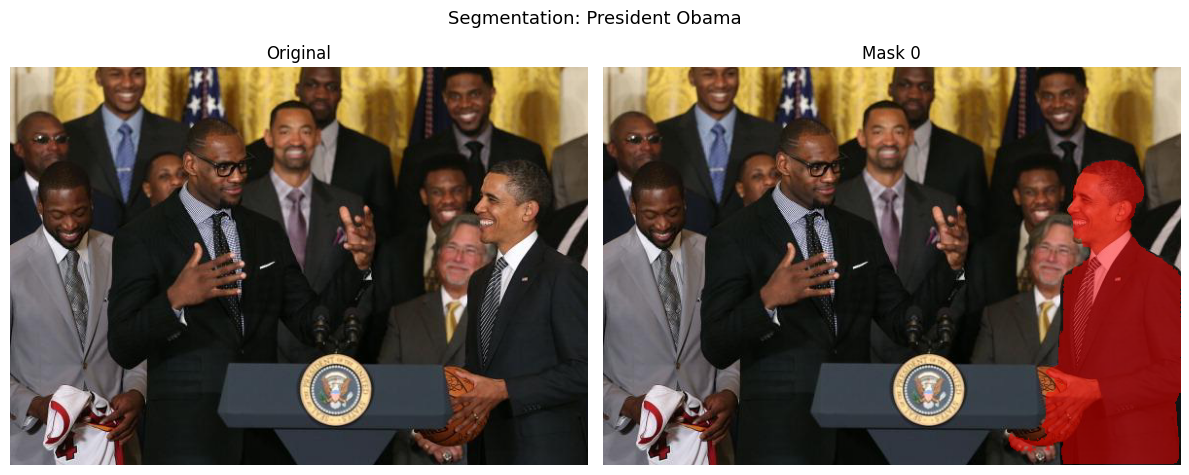

In [ ]:
text_output, pred_masks = run_inference(
    prompt="Who was the president of the US in this image? Please output segmentation mask",
    image_path="imgs/obama.jpg",
)
print("Model response:", text_output.split("ASSISTANT: ")[-1] if "ASSISTANT:" in text_output else text_output)
show_segmentation("imgs/obama.jpg", pred_masks, title="Segmentation: President Obama")

## 4. ReasonSeg Dataset

The **ReasonSeg** dataset contains images paired with complex reasoning-based segmentation queries and ground-truth masks.

In [ ]:
!find /kaggle/input -maxdepth 6 -type d | grep -Ei "reason|reasonseg|reason_seg|/train$|/val$|/test$" | sort | head -n 300


/kaggle/input/datasets/sashadance/reasonseg
/kaggle/input/datasets/sashadance/reasonseg/test
/kaggle/input/datasets/sashadance/reasonseg/test/test
/kaggle/input/datasets/sashadance/reasonseg/train
/kaggle/input/datasets/sashadance/reasonseg/train/train
/kaggle/input/datasets/sashadance/reasonseg/val
/kaggle/input/datasets/sashadance/reasonseg/val/val


In [ ]:
!mkdir -p /kaggle/working/LISA/data/reason_seg/ReasonSeg/{train,val,test}


In [ ]:
!cp -r /kaggle/input/datasets/sashadance/reasonseg/train/train/* /kaggle/working/LISA/data/reason_seg/ReasonSeg/train/
!cp -r /kaggle/input/datasets/sashadance/reasonseg/val/val/*     /kaggle/working/LISA/data/reason_seg/ReasonSeg/val/
!cp -r /kaggle/input/datasets/sashadance/reasonseg/test/test/*   /kaggle/working/LISA/data/reason_seg/ReasonSeg/test/


In [ ]:
# TODO: Define ReasonSeg Dataset here
# ...
from utils.dataset import ValDataset

BASE_DIR = "/kaggle/working/LISA/data"
IMAGE_SIZE = 1024

val_dataset = ValDataset(
    base_image_dir=BASE_DIR,
    tokenizer=tokenizer,
    vision_tower=model.config.vision_tower,
    val_dataset="ReasonSeg|val",
    image_size=IMAGE_SIZE,
)

train_dataset = ValDataset(
    base_image_dir=BASE_DIR,
    tokenizer=tokenizer,
    vision_tower=model.config.vision_tower,
    val_dataset="ReasonSeg|train",
    image_size=IMAGE_SIZE,
)

test_dataset = ValDataset(
    base_image_dir=BASE_DIR,
    tokenizer=tokenizer,
    vision_tower=model.config.vision_tower,
    val_dataset="ReasonSeg|test",
    image_size=IMAGE_SIZE,
)

print(f"Training samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}, Test samples: {len(test_dataset)}")


Training samples: 239, Validation samples: 200, Test samples: 779


In [ ]:
def make_val_dataset_deterministic(val_dataset):
    if getattr(val_dataset, "data_type", None) == "reason_seg":
        val_dataset.images = sorted(val_dataset.images)
    return val_dataset

val_dataset = make_val_dataset_deterministic(val_dataset)

In [ ]:
# TODO: Add here helper functions if needed
# ...


@torch.no_grad()
def infer_on_dataset(dataset, ind, params=PARAMETERS):
    # TODO: Finish implementation
    # ...

    item = dataset[ind]
    image_path = item[0]
    conversations = item[3]

    results = []
    for prompt in conversations:
        p = str(prompt)
        # дублировние убираем
        p = p.replace("<image>", "").replace("<im_start>", "").replace("<im_end>", "").strip()

        text_out, pred_masks = run_inference(p, image_path, params=params)
        results.append((text_out, pred_masks))

    return results


### 4.1. Exploring Dataset Samples

Sample 1 — Sure, the segmentation result is [SEG]  .</s>


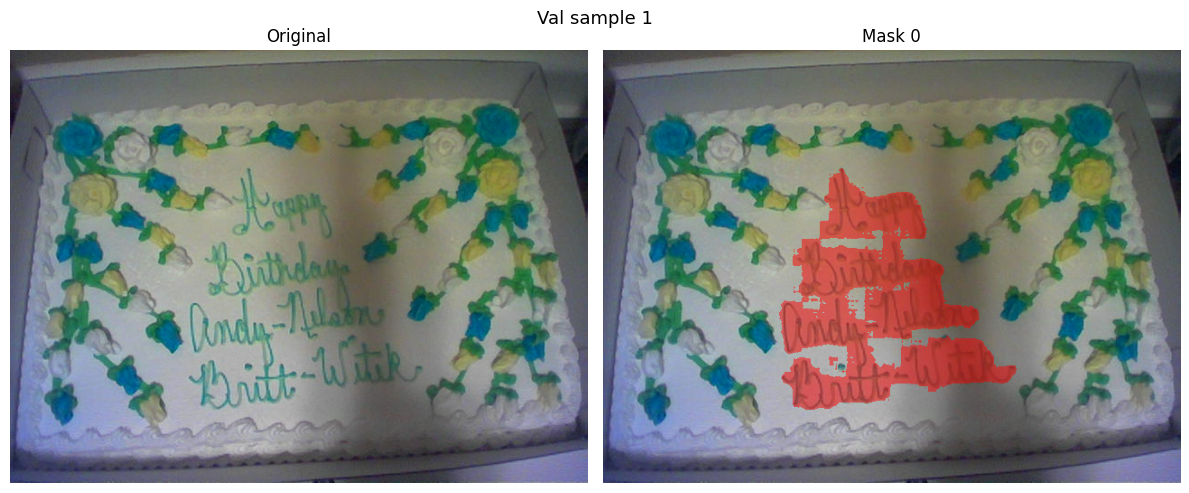

Sample 30 — Sure, it is [SEG]  .</s>


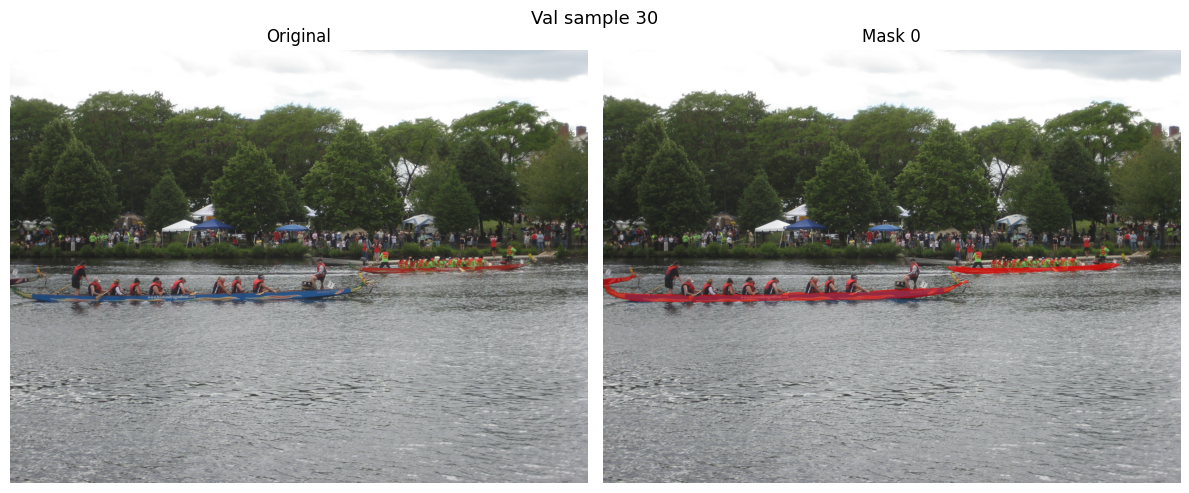

In [ ]:
for ind in [1, 30]:
    results = infer_on_dataset(val_dataset, ind)
    image_path, *_ = val_dataset[ind]
    for text_out, pred_masks in results:
        response = text_out.split("ASSISTANT: ")[-1] if "ASSISTANT:" in text_out else text_out
        print(f"Sample {ind} — {response}")
        show_segmentation(image_path, pred_masks, title=f"Val sample {ind}")

## 5. `[SEG]` Token

**Paper reference:** *"Reasoning to Attend: Try to Understand How \<SEG\> Token Works"*

When LISA generates the `[SEG]` token, its hidden state is projected into the SAM prompt space.
The same projection can be applied to the 256 image-token hidden states that the LLM produces for the CLIP patches.
Computing the dot-product similarity between the projected `[SEG]` embedding and the projected image-patch embeddings reveals
**which spatial regions the `[SEG]` token "attends to"** in the language model's representation space.


In [ ]:
# TODO: Add here helper functions if needed
# ...


@torch.no_grad()
def compute_seg_similarity(prompt, image_path, params=PARAMETERS):
    image_bgr = cv2.imread(image_path)
    image_rgb = image_bgr[..., ::-1]
    original_size = image_rgb.shape[:2]

    image_clip = preprocess_clip(image_rgb, params)
    image_sam, resize_shape = preprocess_sam(image_rgb, params)

    # КОСТЫЛЬ: чистим датасетный prompt от already-inserted image token / служебного текста
    prompt = str(prompt)
    prompt = prompt.replace("<image>", "").replace("<im_start>", "").replace("<im_end>", "")
    prompt = prompt.replace("USER:", "").replace("ASSISTANT:", "").strip()

    full_prompt = build_prompt(prompt, params)
    input_ids = tokenizer_image_token(full_prompt, tokenizer, return_tensors="pt")
    input_ids = input_ids.unsqueeze(0).cuda()

    output_ids, pred_masks = model.evaluate(
        image_clip,
        image_sam,
        input_ids,
        [resize_shape],
        [original_size],
        max_new_tokens=params["max_new_tokens"],
        tokenizer=tokenizer,
    )

    full_ids = torch.cat([input_ids[0], output_ids[0]], dim=0).unsqueeze(0)

    outputs = model(
    input_ids=full_ids,
    images=image_clip,
    attention_mask=torch.ones_like(full_ids),
    past_key_values=None, ## переделать эту часть
    output_hidden_states=True,
    return_dict=True,
)

    last_hidden = outputs.hidden_states[-1]

    seg_positions = (full_ids[0] == seg_token_idx).nonzero(as_tuple=True)[0]
    if len(seg_positions) == 0:
        h, w = image_rgb.shape[:2]
        return np.zeros((h, w, 3), dtype=np.uint8), pred_masks
    seg_pos = seg_positions[0].item()
    seg_emb = last_hidden[0, seg_pos]

    image_token_positions = (input_ids[0] == IMAGE_TOKEN_INDEX).nonzero(as_tuple=True)[0]
    img_start = image_token_positions[0].item()
    image_emb = last_hidden[0, img_start:img_start + 256]

    proj = model.text_hidden_fcs[0]
    seg_proj = proj(seg_emb.unsqueeze(0))
    image_proj = proj(image_emb)

    sim = F.cosine_similarity(seg_proj, image_proj, dim=-1)
    sim = sim.float().cpu().numpy().reshape(16, 16)

    sim = (sim - sim.min()) / (sim.max() - sim.min() + 1e-8)
    h, w = image_rgb.shape[:2]
    heatmap = cv2.resize(sim, (w, h), interpolation=cv2.INTER_CUBIC)

    heatmap_color = (plt.cm.jet(heatmap)[:, :, :3] * 255).astype(np.uint8)
    overlay = (0.5 * image_rgb + 0.5 * heatmap_color).astype(np.uint8)

    return overlay, pred_masks


In [ ]:
sample_indices = [5, 9, 11, 16, 19]

for ind in sample_indices:
    # TODO: Finish implementation
    # ...
    item = train_dataset[ind]
    image_path = item[0]
    conversations = item[3]
    masks = item[4]

    image_bgr = cv2.imread(image_path)
    image_np = image_bgr[..., ::-1]

    prompt = conversations[0]

    similarity_overlay, pred_masks = compute_seg_similarity(
        prompt=prompt,
        image_path=image_path,
    )

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(image_np)
    axes[0].set_title("Image")
    axes[0].axis("off")

    axes[1].imshow(masks[0], cmap="gray")
    axes[1].set_title("Ground Truth")
    axes[1].axis("off")

    if pred_masks and pred_masks[0].numel() > 0:
        axes[2].imshow(overlay_mask(image_np, pred_masks[0]))
        axes[2].set_title("LISA Prediction")
        axes[2].axis("off")
    else:
        axes[2].set_visible(False)

    axes[3].imshow(similarity_overlay)
    axes[3].set_title("[SEG] Similarity")
    axes[3].axis("off")

    fig.suptitle(f"Train sample {ind} — {conversations[0][:80]}...", fontsize=11)
    plt.tight_layout()
    plt.show()


IndexError: index 1 is out of bounds for dimension 0 with size 1

## 6. **Layer-wise Probing** — When Does Spatial Grounding Emerge?


**Paper reference:** *Belrose et al., "Eliciting Latent Predictions from Transformers with the Tuned Lens", NeurIPS 2023.*

The *logit lens* technique projects intermediate layer representations into the output vocabulary to observe when a prediction crystallises.
In LISA the analogous question is: **at which transformer layer does the `[SEG]` token's hidden state already encode enough spatial information to produce a correct segmentation mask?**

To answer this, we project the `[SEG]` representation at *every* layer through `text_hidden_fcs` (trained only on the last layer) and feed the resulting 256-d vector to the frozen SAM decoder.

**Task.**
1. Run a full forward pass with `output_hidden_states=True` to obtain the `[SEG]` hidden state at all 40 LLaMA layers.
2. For each layer, project through `text_hidden_fcs`, then run the SAM decoder to obtain a mask.
3. Compute IoU of every layer's mask against the ground-truth.
4. Plot **IoU vs. layer index** and show masks at all layers.
5. *At which depth does grounding emerge? Is the transition gradual or abrupt?*

In [ ]:
from utils.utils import intersectionAndUnionGPU

def calculate_iou(y_pred: torch.Tensor, y_true: torch.Tensor) -> float:
    # TODO: Finish implementation
    # ...
    return ...


In [ ]:
# TODO: Add here helper functions if needed
# ...


In [ ]:
@torch.no_grad()
def layerwise_probing(dataset, ind, store_all_masks=False):
    """Probe each LLM layer's [SEG] embedding and decode to mask via SAM."""
   
   # TODO: Finish implementation
   # ...

    return {
        "ious": ious,
        "layer_masks": layer_masks,
        "gt_mask": gt_mask,
        "image_path": image_path,
        "num_layers": num_layers,
        "conversations": conversations,
    }

In [ ]:
def get_baseline_prediction(dataset, ind, gt_mask):
    """Run standard LISA inference and compute IoU with ground truth."""
    # TODO: Finish implementation
    # ...

    return baseline_iou, baseline_mask


def plot_iou_curve(ious, baseline_iou, sample_ind, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 4))
    
    num_layers = len(ious)
    x = range(num_layers)
    
    ax.plot(x, ious, color='#2196F3', linewidth=2, marker='o', markersize=4, label='Layer-wise probing')

    # Baseline horizontal line
    ax.axhline(y=baseline_iou, color='#F44336', linestyle='--', linewidth=2, label=f'LISA baseline ({baseline_iou:.3f})')
    
    # Highlight best layer
    best_idx = int(np.argmax(ious))
    ax.scatter([best_idx], [ious[best_idx]], color='#4CAF50', s=150, zorder=5, 
               label=f'Best: Layer {best_idx} ({ious[best_idx]:.3f})')
    
    # Mark final layer (LISA uses this)
    ax.scatter([num_layers - 1], [ious[-1]], color='#FF9800', s=100, zorder=5, marker='s',
               label=f'Final layer ({ious[-1]:.3f})')
    
    ax.set_xlabel('Layer Index', fontsize=11)
    ax.set_ylabel('IoU', fontsize=11)
    ax.set_title(f'Sample {sample_ind} — Segmentation IoU Across LLM Layers', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-0.5, num_layers - 0.5)
    ax.set_ylim(0, 1.05)
    
    return ax


def plot_all_layer_masks(result, image_np, gt_mask, baseline_mask, baseline_iou, sample_ind):
    layer_masks = result["layer_masks"]
    ious = result["ious"]
    num_layers = result["num_layers"]
    
    # Calculate grid dimensions (8 columns for ~40 layers)
    n_cols = 8
    n_rows = (num_layers + 3) // n_cols + 1  # +3 for image, GT, baseline
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 2.5))
    axes = axes.flatten()
    
    for ax in axes:
        ax.axis('off')
    
    # Panel 0: Original image
    axes[0].imshow(square_pad(image_np))
    axes[0].set_title('Input Image', fontsize=9, fontweight='bold')
    axes[0].axis('off')
    
    # Panel 1: Ground truth
    axes[1].imshow(square_pad(gt_mask.numpy() if hasattr(gt_mask, 'numpy') else gt_mask), cmap='gray')
    axes[1].set_title('Ground Truth', fontsize=9, fontweight='bold')
    axes[1].axis('off')
    
    # Panel 2: LISA baseline
    axes[2].imshow(square_pad(baseline_mask), cmap='gray')
    axes[2].set_title(f'LISA Baseline\nIoU={baseline_iou:.3f}', fontsize=9, fontweight='bold', color='#F44336')
    axes[2].axis('off')
    
    # Panels 3+: Layer masks
    best_layer = int(np.argmax(ious))
    
    for i, layer_idx in enumerate(sorted(layer_masks.keys())):
        ax_idx = i + 3
        if ax_idx >= len(axes):
            break
            
        mask = layer_masks[layer_idx]
        iou = ious[layer_idx]
        
        axes[ax_idx].imshow(square_pad(mask), cmap='gray')
        
        if layer_idx == best_layer:
            color = '#4CAF50' 
            title = f'L{layer_idx} ★\nIoU={iou:.3f}'
        elif layer_idx == num_layers - 1:
            color = '#FF9800' 
            title = f'L{layer_idx} (final)\nIoU={iou:.3f}'
        else:
            color = 'black'
            title = f'Layer {layer_idx}\nIoU={iou:.3f}'
        
        axes[ax_idx].set_title(title, fontsize=8, color=color)
        axes[ax_idx].axis('off')
    
    fig.suptitle(f'Sample {sample_ind} — Layer-wise Mask Predictions', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    return fig

In [ ]:
sample_indices = [21, 22, 23]  # Modify as needed

for ind in sample_indices:
    print(f"\n{'='*60}")
    print(f"Analyzing Sample {ind}")
    print(f"{'='*60}")
    
    # Run layer-wise probing (store ALL masks for full visualization)
    result = layerwise_probing(test_dataset, ind, store_all_masks=True)
    
    if result is None:
        continue
    
    gt_mask = result["gt_mask"]
    image_path = result["image_path"]
    image_np = cv2.imread(image_path)[..., ::-1]
    
    baseline_iou, baseline_mask = get_baseline_prediction(test_dataset, ind, gt_mask)
    
    ious = result["ious"]
    print(f"  Prompt: {result['conversations'][0][:80]}...")
    print(f"  Number of layers: {result['num_layers']}")
    print(f"  LISA baseline IoU: {baseline_iou:.4f}")
    print(f"  Final layer IoU:   {ious[-1]:.4f}")
    print(f"  Best layer: {np.argmax(ious)} with IoU={max(ious):.4f}")
    
    fig1, ax1 = plt.subplots(figsize=(14, 4))
    plot_iou_curve(ious, baseline_iou, ind, ax=ax1)
    plt.tight_layout()
    plt.show()
    
    fig2 = plot_all_layer_masks(result, image_np, gt_mask, baseline_mask, baseline_iou, ind)
    plt.show()

### 7. Geometry of the `[SEG]` Embedding Space

**Paper reference:** *Meng et al., "Locating and Editing Factual Associations in GPT", NeurIPS 2022.*

Meng et al. introduced *causal tracing* — surgically modifying hidden representations and measuring the downstream effect — to localise where factual knowledge is stored in LLMs.
Applied to LISA, we can probe the **geometry of the 256-d `[SEG]` embedding space** that bridges the LLM and SAM:

* If two prompts targeting *different* objects on the same image yield embeddings **A** and **B**, does linearly interpolating between them produce masks that smoothly morph from object A to object B?

**Task.**
1. Select an image with two distinct objects. Run LISA with two different prompts → embeddings **A** and **B**.
2. Compute 7 linear interpolations: α ∈ {0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0}.
3. Decode each interpolated embedding through SAM and visualise the mask sequence.

In [ ]:
# TODO: Add here helper functions if needed
# ...


@torch.no_grad()
def interpolation_experiment(dataset, ind, prompt_a, prompt_b, n_steps=7):
    # TODO: Finish implementation
    # ...

    alphas = np.linspace(0, 1, n_steps)
    interp_masks = []
    for alpha in alphas:
        ...

    return dict(
        alphas=alphas, 
        interp_masks=interp_masks, 
        image_path=image_path, 
        gt_mask=masks[0],
        prompt_a=prompt_a, 
        prompt_b=prompt_b
    )

In [ ]:
experiments = [
    # You can change the prompts here
    (0, "the largest object", "the background"),
    (10, "the dog", "the pants"),
    (30, "the left dog", "the right dog"),
]

for ind, prompt_a, prompt_b in experiments:
    result = interpolation_experiment(train_dataset, ind, prompt_a, prompt_b)
    if result is None:
        continue

    n = len(result["alphas"]) + 1
    fig, axes = plt.subplots(1, n, figsize=(3.5 * n, 4))
    
    axes[0].imshow(cv2.imread(result["image_path"])[..., ::-1]); axes[0].set_title("Image")
    axes[0].axis("off")
    
    for j, (alpha, mask) in enumerate(zip(result["alphas"], result["interp_masks"])):
        axes[j + 1].imshow(mask, cmap="gray"); axes[j + 1].set_title(f"α={alpha:.2f}")
        axes[j + 1].axis("off")
    
    fig.suptitle(f'Sample {ind}: "{prompt_a}" → "{prompt_b}"', fontsize=11)
    plt.tight_layout(); plt.show()